# Características de huellas: primera representación GLCM
**Trabajo Final IA I 2026 · UNCUYO · Hito 1**

Este notebook explica y comprueba los vectores generados por `src/extraer_dataset_huellas.py`. No entrena modelos ni ajusta PCA o escaladores. Los ejemplos se toman de entrenamiento; la prueba final queda reservada.

Antes de ejecutarlo, desde la raíz del repositorio:
```powershell
.\.venv\Scripts\python.exe src/extraer_dataset_huellas.py --verificar-180
```
Seleccionar el kernel de `.venv` en VS Code. Las salidas que obtengas documentarán **tu ejecución local**; los resultados del asistente están separados en `documentos/historico/verificacion_caracteristicas_huellas_asistente.json`.


## 1. Qué información buscamos
Una huella presenta crestas y valles: una textura con orientación y separación local. La matriz de coocurrencia (GLCM) cuenta pares de intensidades a cierto desplazamiento. Al normalizar esos conteos obtenemos probabilidades y resumimos su contraste, homogeneidad, energía y correlación.

La Clase 10 (diapositiva 45) presenta este enfoque. Es un candidato inicial explicable, **no una garantía de identificación**. Distintas identidades pueden tener estadísticas parecidas; todavía no se midió reconocimiento.

Se usan 16 niveles, distancias nominales 1/3/5 píxeles y direcciones 0°/45°/90°/135°. La cuantización y los percentiles 2–98 se aplican a cada muestra, sin aprender del conjunto. No se incorporan etiquetas como variables predictivas.


## Idea general de la vectorización

Cada imagen contiene miles de píxeles. El objetivo es reemplazarla por una lista
más pequeña y ordenada que describa su textura:

$$\mathbf{x}_{huella}=[x_1,x_2,\ldots,x_{144}].$$

La identidad, el identificador y la partición se conservan en el catálogo y no
entran en el vector. Más adelante podremos comparar huellas mediante distancias
entre estos vectores, siempre después de aplicar el escalador aprendido con
entrenamiento autorizado.


In [1]:
from pathlib import Path
from collections import Counter
import csv, hashlib, importlib.metadata, json, sys
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config/caracteristicas_huellas_glcm_v1.json").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abrí el notebook dentro del repositorio.")
sys.path.insert(0, str(RAIZ / "src")) if str(RAIZ / "src") not in sys.path else None
from caracteristicas_huellas import (cargar_config, preparar_huella, extraer_huella,
                                    nombres_caracteristicas, contar_pares, medidas_glcm)

def leer_json(path):
    return json.loads(path.read_text(encoding="utf-8-sig"))
def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

# Para consultar un corte anterior, copiar aquí su ruta relativa exacta.
SALIDA_RELATIVA = ""
cfg = cargar_config()
if SALIDA_RELATIVA:
    SALIDA = RAIZ / SALIDA_RELATIVA
else:
    versiones = {p: importlib.metadata.version(p) for p in ("numpy", "scipy", "Pillow")}
    candidatos = []
    for p in (RAIZ / "datos/caracteristicas/huellas").glob("*/ejecucion_*/manifiesto.json"):
        if p.parent.name.endswith(".parcial"):
            continue
        m = leer_json(p)
        contrato = m["contrato"]
        if (contrato["config"] == cfg and contrato["dependencias"] == versiones
                and all(sha(RAIZ / "src" / n) == v for n, v in contrato["codigo"].items())):
            candidatos.append(p.parent)
    if not candidatos:
        raise FileNotFoundError("Ejecutá primero el extractor con la configuración y el código actuales.")
    ids = {p.parent.name for p in candidatos}
    if len(ids) != 1:
        raise ValueError("Hay distintas versiones de normalización: indicar SALIDA_RELATIVA explícitamente.")
    SALIDA = sorted(candidatos, key=lambda p: p.name)[-1]

manifiesto = leer_json(SALIDA / "manifiesto.json")
resumen = leer_json(SALIDA / "resumen.json")
cfg = leer_json(SALIDA / "config_efectiva.json")
with (SALIDA / "catalogo_caracteristicas.csv").open(encoding="utf-8-sig", newline="") as f:
    filas = list(csv.DictReader(f))
with np.load(SALIDA / "vectores.npz", allow_pickle=False) as datos:
    X, muestras, nombres = datos["X"].copy(), datos["muestras"].copy(), datos["nombres"].copy()
print("Ejecución:", SALIDA.relative_to(RAIZ))
print(json.dumps(resumen, ensure_ascii=False, indent=2))


Ejecución: datos\caracteristicas\huellas\glcm_opuestas_v1_89a0f3928fb3\ejecucion_20261020T123654_145380Z
{
  "id_extractor": "glcm_opuestas_v1_89a0f3928fb3",
  "ejecucion": "ejecucion_20261020T123654_145380Z",
  "total_catalogo": 220,
  "estados": {
    "vectorizada": 170,
    "diferida_prueba": 50
  },
  "forma_X": [
    170,
    144
  ],
  "valores_finitos": true,
  "vectorizadas_por_particion": {
    "entrenamiento": 120,
    "validacion": 50
  },
  "muestras_con_avisos_extractor": 0,
  "vectorizadas_con_aviso_normalizacion": 2,
  "verificadas_180": 170,
  "diferencia_max_180": 0.0,
  "salida": "datos/caracteristicas/huellas/glcm_opuestas_v1_89a0f3928fb3/ejecucion_20261020T123654_145380Z",
  "nota": "Vectorizable no significa aprobada para modelado ni identidad reconocida."
}


## 2. Contrato de filas y columnas
`X` contiene solamente los números del descriptor. `muestras` contiene sus identificadores y `nombres` define el orden de columnas. El catálogo conserva identidad, partición y procedencia fuera de la matriz.

Una fila de catálogo fallida o diferida no tiene `fila_vector`; por eso no se debe emparejar por posición sin comprobar los IDs. Repetir una extracción crea otro corte y no altera los anteriores.


In [2]:
for nombre, digest in manifiesto["sha256_archivos"].items():
    assert sha(SALIDA / nombre) == digest, f"Archivo cambiado: {nombre}"
assert X.shape == (len(muestras), len(nombres))
assert len(set(muestras)) == len(muestras)
assert len(set(nombres)) == len(nombres)
assert np.isfinite(X).all()
assert nombres.tolist() == leer_json(SALIDA / "nombres_caracteristicas.json")
assert nombres.tolist() == nombres_caracteristicas(cfg)
assert X.shape[1] == 3 * len(cfg["distancias_px"]) * 4 * 4
with (SALIDA / "catalogo_origen.csv").open(encoding="utf-8-sig", newline="") as f:
    originales = {r["muestra"]: r for r in csv.DictReader(f)}
indices = []
for r in filas:
    for campo, valor in originales[r["muestra"]].items():
        assert r[campo] == valor, (r["muestra"], campo)
    if r["estado_extraccion"] == "vectorizada":
        k = int(r["fila_vector"])
        assert muestras[k] == r["muestra"]
        indices.append(k)
    else:
        assert r["fila_vector"] == ""
assert sorted(indices) == list(range(len(muestras)))
print("Integridad, dimensiones, valores finitos y correspondencia: OK")
print("Estados:", dict(Counter(r["estado_extraccion"] for r in filas)))
print("Dimensión:", X.shape[1])
print("No hay etiquetas en X ni transformaciones globales ajustadas.")


Integridad, dimensiones, valores finitos y correspondencia: OK
Estados: {'vectorizada': 170, 'diferida_prueba': 50}
Dimensión: 144
No hay etiquetas en X ni transformaciones globales ajustadas.


## 3. Una muestra, paso a paso
Se elige la primera muestra autorizada de entrenamiento en orden de ID, sin buscar una que se vea especialmente favorable.

La máscara se erosiona 6 píxeles para retirar el margen agregado por la normalización. Solo sus píxeles participan en los percentiles. Una GLCM cuenta pares con **ambos extremos válidos**; el color del fondo no influye.

Las regiones opuestas se agrupan: NO+SE y NE+SO. Los pares se cuentan dentro de cada cuadrante y luego se suman las matrices. La región global se conserva como tercer bloque. Las tres regiones de descripción no son tres muestras.


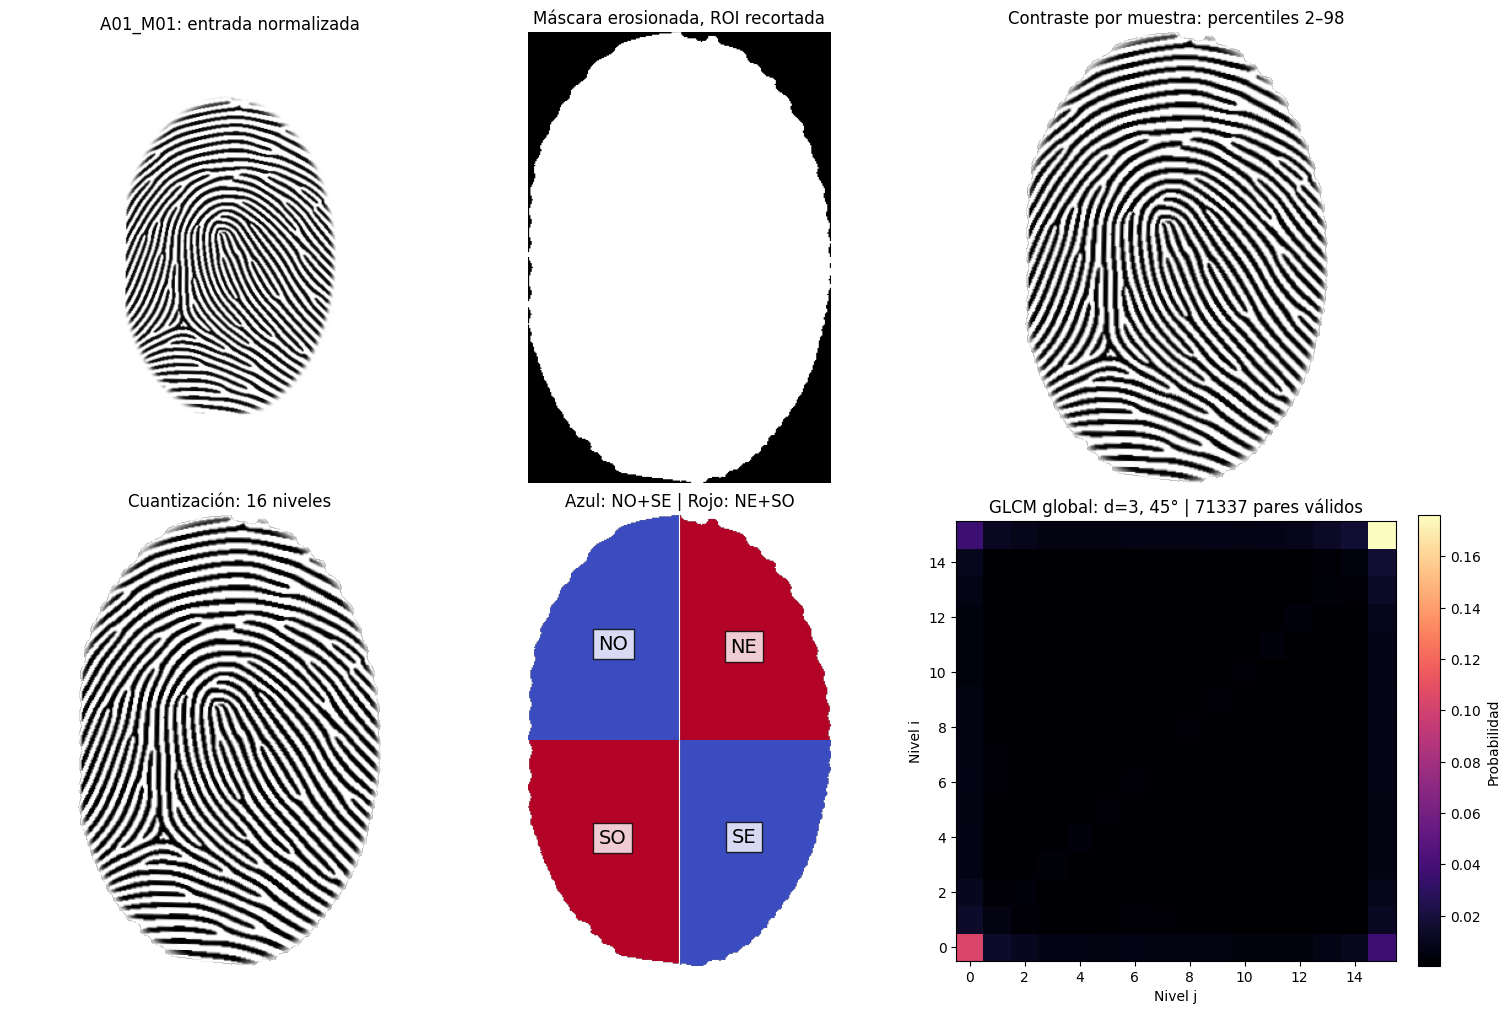

Percentiles de entrada: 8.0 255.0
Áreas válidas: {'global': 72277, 'NO': 18221, 'NE': 17396, 'SO': 18459, 'SE': 17836}
Medidas del ejemplo: {'contraste': 0.23148193317165944, 'homogeneidad': 0.3957229406186248, 'energia': 0.22104425552311288, 'correlacion': 0.35760239704843105}


In [3]:
r = sorted((r for r in filas if r["particion"] == "entrenamiento"
            and r["grupo"] == "autorizado" and r["estado_extraccion"] == "vectorizada"),
           key=lambda r: r["muestra"])[0]
# Evitar mostrar una imagen modificada respecto de la extracción.
assert sha(RAIZ / r["normalizada"]) == r["sha256_entrada_leida"]
assert sha(RAIZ / r["mascara_caracteristicas"]) == r["sha256_mascara_caracteristicas"]
with Image.open(RAIZ / r["normalizada"]) as f:
    im = np.array(f)
with Image.open(RAIZ / r["mascara_caracteristicas"]) as f:
    mask = np.array(f)
q, regiones, acondicionado, info = preparar_huella(im, mask, cfg)
v, diagnostico = extraer_huella(im, mask, cfg)
np.testing.assert_allclose(v, X[int(r["fila_vector"])], atol=1e-12, rtol=0)

# Ejemplo visual: d=3, dirección 45°, desplazamiento real (2,2).
C, cantidad = contar_pares(q, regiones["global"], 2, 2, cfg["niveles"])
medidas, constante, P = medidas_glcm(C)
mapa = np.full(q.shape, np.nan)
mapa[regiones["NO"] | regiones["SE"]] = 1
mapa[regiones["NE"] | regiones["SO"]] = 2

fig, ax = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
ax[0, 0].imshow(im, cmap="gray", vmin=0, vmax=255)
ax[0, 0].set_title(f"{r['muestra']}: entrada normalizada")
ax[0, 1].imshow(regiones["global"], cmap="gray")
ax[0, 1].set_title("Máscara erosionada, ROI recortada")
ax[0, 2].imshow(np.ma.array(acondicionado, mask=~regiones["global"]), cmap="gray", vmin=0, vmax=1)
ax[0, 2].set_title("Contraste por muestra: percentiles 2–98")
ax[1, 0].imshow(np.ma.array(q, mask=~regiones["global"]), cmap="gray", vmin=0, vmax=15)
ax[1, 0].set_title("Cuantización: 16 niveles")
ax[1, 1].imshow(mapa, cmap="coolwarm", vmin=1, vmax=2)
ax[1, 1].set_title("Azul: NO+SE | Rojo: NE+SO")
for nombre in ("NO", "NE", "SO", "SE"):
    yy, xx = np.where(regiones[nombre])
    ax[1, 1].text(xx.mean(), yy.mean(), nombre, ha="center", va="center",
                  fontsize=14, color="black", bbox=dict(facecolor="white", alpha=.8))
g = ax[1, 2].imshow(P, origin="lower", cmap="magma")
ax[1, 2].set_title(f"GLCM global: d=3, 45° | {cantidad} pares válidos")
ax[1, 2].set_xlabel("Nivel j"); ax[1, 2].set_ylabel("Nivel i")
fig.colorbar(g, ax=ax[1, 2], label="Probabilidad")
for a in ax.flat:
    if a is not ax[1, 2]:
        a.axis("off")
plt.show()
print("Percentiles de entrada:", info["percentil_bajo"], info["percentil_alto"])
print("Áreas válidas:", info["pixeles_regiones"])
print("Medidas del ejemplo:", dict(zip(["contraste", "homogeneidad", "energia", "correlacion"], medidas)))


## 4. Por qué el giro de 180° no duplica los datos
Al girar imagen y máscara, NO y SE se intercambian, al igual que NE y SO. Las sumas de conteos se mantienen, salvo la transposición causada por invertir el sentido de los pares. La simetrización `C + C.T` elimina ese último cambio.

Esto pierde la ubicación dentro de cada pareja opuesta. No elimina las diferencias por desenfoque, rotaciones arbitrarias o recorte. Si concatenáramos los cuatro cuadrantes sin emparejarlos, la simetrización no bastaría.


In [4]:
v180, _ = extraer_huella(np.rot90(im, 2), np.rot90(mask, 2), cfg)
error = float(np.max(np.abs(v-v180)))
np.testing.assert_allclose(v, v180, atol=1e-12, rtol=0)
print("Muestra:", r["muestra"], "| Diferencia máxima:", error)
print("Comprobaciones 180° del lote:", resumen["verificadas_180"])
print("Máximo del lote:", resumen["diferencia_max_180"])


Muestra: A01_M01 | Diferencia máxima: 0.0
Comprobaciones 180° del lote: 170
Máximo del lote: 0.0


## 5. El vector de 144 componentes
Orden: **global / NO_SE / NE_SO → distancias 1/3/5 → ángulos 0/45/90/135 → contraste / homogeneidad / energía / correlación**.

Cada panel grafica una medida para los 36 grupos de parámetros. Las líneas verticales separan los tres bloques espaciales. Estas son características **sin escalado aprendido**; dividir el contraste por el rango máximo es parte de su fórmula.

Los gráficos sirven para comprender la extracción, no para concluir que las identidades están separadas.


Primeras 12 características:
global_d1_a0_contraste                 0.05886302
global_d1_a0_homogeneidad              0.56740778
global_d1_a0_energia                   0.32095785
global_d1_a0_correlacion               0.83614495
global_d1_a45_contraste                0.08606467
global_d1_a45_homogeneidad             0.56517094
global_d1_a45_energia                  0.30461740
global_d1_a45_correlacion              0.76048800
global_d1_a90_contraste                0.06565975
global_d1_a90_homogeneidad             0.54083751
global_d1_a90_energia                  0.31290752
global_d1_a90_correlacion              0.81716378
Última: NE_SO_d5_a135_correlacion = -0.43741589818719434


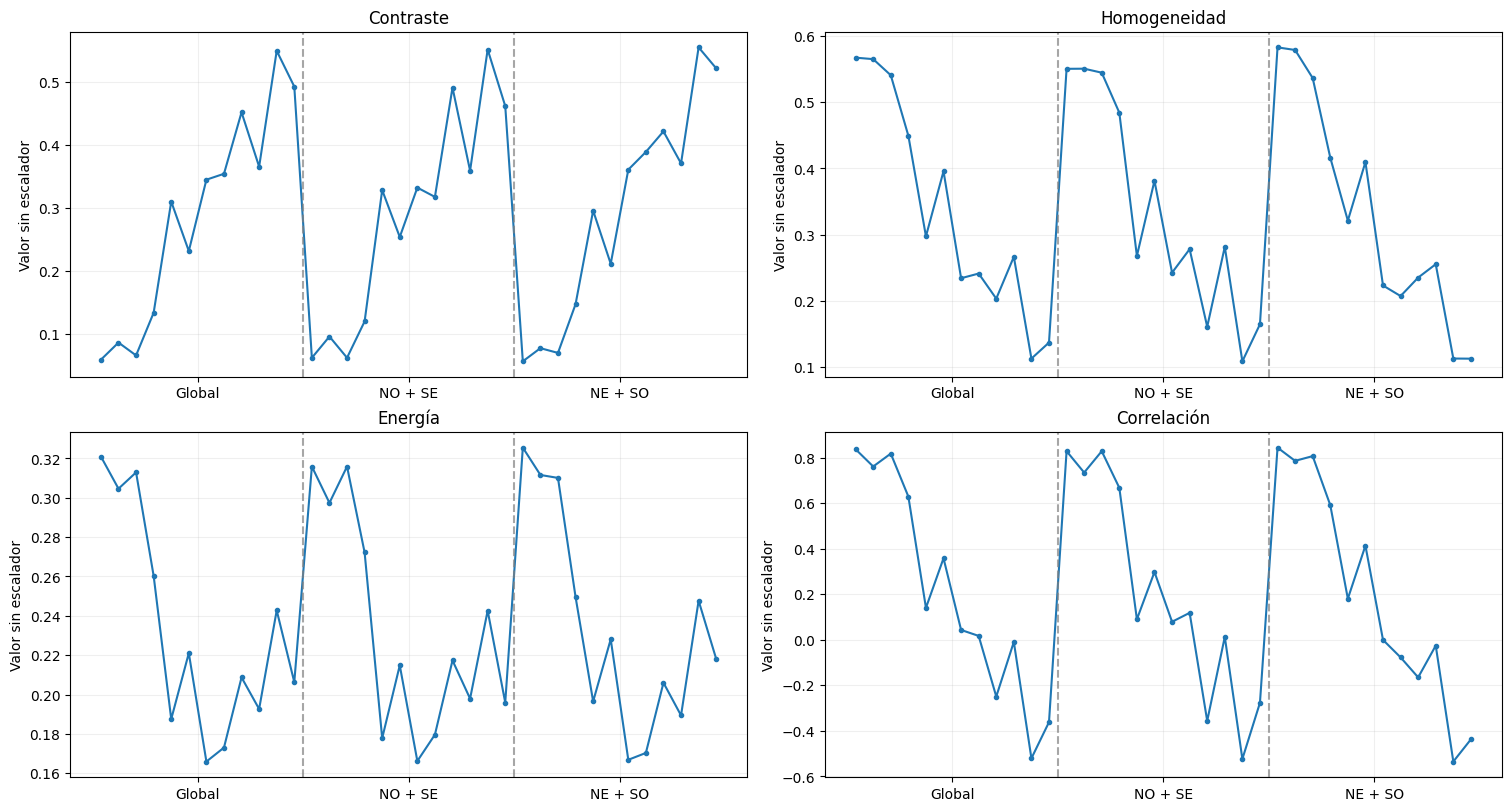

In [5]:
print("Primeras 12 características:")
for nombre, valor in zip(nombres[:12], v[:12]):
    print(f"{nombre:38s} {valor:.8f}")
print("Última:", nombres[-1], "=", v[-1])
fig, axs = plt.subplots(2, 2, figsize=(15, 8), constrained_layout=True)
for k, (ax, medida) in enumerate(zip(axs.flat, ["Contraste", "Homogeneidad", "Energía", "Correlación"])):
    ax.plot(np.arange(36), v[k::4], marker="o", markersize=3, linewidth=1.5)
    for limite in [11.5, 23.5]: ax.axvline(limite, color="gray", linestyle="--", alpha=.7)
    ax.set_xticks([5.5, 17.5, 29.5], ["Global", "NO + SE", "NE + SO"])
    ax.set_title(medida); ax.set_ylabel("Valor sin escalador")
    ax.grid(alpha=.2)
plt.show()


## 6. Avisos y cierre de este hito
Una muestra puede ser vectorizable y conservar advertencias. Las regiones pequeñas o sin suficientes pares se rechazan técnicamente; no se rellenan con ceros. Las matrices constantes usan correlación 1 por convenio y lo informan. Una imagen completamente constante no supera el control de contraste.

Revisamos solo avisos de desarrollo. No usamos prueba para ajustar parámetros ni para elegir métodos.


In [6]:
print("Avisos o problemas de desarrollo:")
hay = False
for rr in filas:
    if rr["particion"] == "prueba":
        continue
    anteriores = json.loads(rr["avisos_normalizacion_json"])
    nuevos = json.loads(rr["avisos_extraccion_json"])
    if anteriores or nuevos or rr["motivo_extraccion"]:
        hay = True
        print(rr["muestra"], rr["estado_extraccion"], "| Normalización:", anteriores,
              "| Extracción:", nuevos, "| Motivo:", rr["motivo_extraccion"])
if not hay:
    print("Sin avisos registrados en desarrollo.")
print("Pendiente: revisión local, luego audio y finalmente escalado/PCA.")


Avisos o problemas de desarrollo:
A01_M43 vectorizada | Normalización: ['La región alcanza un borde de la entrada: posible recorte previo.'] | Extracción: [] | Motivo: 
A02_M44 vectorizada | Normalización: ['La región alcanza un borde de la entrada: posible recorte previo.'] | Extracción: [] | Motivo: 
Pendiente: revisión local, luego audio y finalmente escalado/PCA.


## Referencias, límites y registro
- Consigna: `Trabajo Final 2026.pdf`, pp. 3–4.
- Clase 10 — Percepción 2026, diapositivas 45–49.
- [Documentación oficial GLCM](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.graycomatrix) y [medidas](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.graycoprops).
- Decisiones, fórmulas, rutas y resultados del asistente: `documentos/etapas/caracteristicas_huellas_hito1.md`.

La implementación conserva NumPy, SciPy, Pillow y Matplotlib del entorno existente. Fue asistida por ChatGPT y verificada con pruebas de fórmulas, máscaras, invariancia y trazabilidad. No se atribuyen resultados de reconocimiento a estos controles.

**Registro a completar después de ejecutar en Windows:** fecha, entorno, forma de X, errores/avisos, revisión visual y dificultades encontradas. Mantener la salida de prueba fuera de las decisiones de desarrollo. No hace falta ejecutar K-means ni PCA para aprobar el funcionamiento mecánico de este hito.


## Relación con K-means y el rechazo de intrusos

En la etapa posterior, K-means aprenderá centros utilizando huellas autorizadas
de entrenamiento. Luego se estudiará qué identidades aparecen alrededor de
cada centro. Para una huella nueva se repetirá la normalización, se calculará el
mismo vector de 144 componentes y se aplicará el escalador guardado.

K-means siempre encuentra un centro cercano, incluso para una huella intrusa.
Por eso la identidad no se decidirá únicamente por el nombre del grupo: hará
falta estudiar las distancias y ajustar una regla de rechazo con desarrollo y
validación. Las 50 muestras de prueba continúan reservadas durante esas
selecciones.

La separación aparente en un gráfico PCA no demuestra reconocimiento. PCA se
ajustará con entrenamiento y servirá primero para visualizar si existen
agrupamientos, superposiciones o valores atípicos.

Las huellas usadas hasta aquí son sintéticas. Una captura de un sensor físico
puede tener otra iluminación, resolución y textura; deberá evaluarse con datos
del dispositivo antes de afirmar que reconoce huellas reales.
